# Predicting Severe Building Damage from the 2015 Nepal Earthquake in Gorkha District Using Decision Trees and Hyperparameter Tuning (max_depth)

1. Import Library

- pandas, numpy, matplotlib: Olah data dan visualisasi
- DecisionTreeClassifier, plot_tree: Model pohon keputusan dan visualisasinya
- accuracy_score: Metrik evaluasi
- train_test_split: Pembagian data
- OrdinalEncoder (category_encoders): Mengubah kategori menjadi angka berurutan
- Pipeline: Menggabungkan encoder dan model dalam satu alur

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from category_encoders import OrdinalEncoder
from sklearn.pipeline import Pipeline

# Set display options
# pd.set_option('display.max_columns', None)

2. Memuat Data

- wrangle_nepal_data(district_id=4) → memuat data Gorkha dari modul buatan sendiri.
- Hasil: 70.836 baris × 7 kolom, tingkat kerusakan parah 64,26%.

In [2]:
from duckdb_wrangle import wrangle_nepal_data

# Load Gorkha district data (district_id = 4) from the `data` folder
df = wrangle_nepal_data(district_id=4)

print(f"Dataset shape: {df.shape}")
print(f"Columns: {list(df.columns)}")
print(f"\nSevere damage rate: {df['severe_damage'].mean():.2%}")

Dataset shape: (70836, 7)
Columns: ['district_id', 'age_building', 'plinth_area_sq_ft', 'height_ft_pre_eq', 'foundation_type', 'ground_floor_type', 'severe_damage']

Severe damage rate: 64.26%


3. Fitur dan Target

- target = 'severe_damage', features = semua kolom lain (6 fitur).
- X = df[features], y = df[target].

In [3]:
# Define target and features
target = 'severe_damage'
features = [col for col in df.columns if col != target]

# Create X and y
X = df[features]   # <-- feature matrix
y = df[target]   # <-- target vector

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"Features: {features}")

X shape: (70836, 6)
y shape: (70836,)
Features: ['district_id', 'age_building', 'plinth_area_sq_ft', 'height_ft_pre_eq', 'foundation_type', 'ground_floor_type']


4. Pembagian Data 3 Bagian

- Split pertama: 20% untuk test set.
- Split kedua: 25% dari sisanya untuk validation set (= 20% total).
- Hasil: Train 42.501 (60%), Validation 14.167 (20%), Test 14.168 (20%).
- Validation set dipakai untuk memilih hyperparameter, test set disimpan untuk evaluasi akhir.

In [4]:
# First split: separate test set (20%)
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Second split: separate validation from training (25% of 80% = 20% overall)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=42
)

print(f"Training set: {X_train.shape[0]} samples ({X_train.shape[0]/len(X):.1%})")
print(f"Validation set: {X_val.shape[0]} samples ({X_val.shape[0]/len(X):.1%})")
print(f"Test set: {X_test.shape[0]} samples ({X_test.shape[0]/len(X):.1%})")

Training set: 42501 samples (60.0%)
Validation set: 14167 samples (20.0%)
Test set: 14168 samples (20.0%)


5. Akurasi Baseline

- Prediksi kelas mayoritas selalu → 64,20%.

In [5]:
# Calculate baseline (predict majority class)
baseline_acc = y_train.value_counts(normalize=True).max()

print(f"Baseline Accuracy: {baseline_acc:.4f}")
print(f"Majority class: {y_train.value_counts().idxmax()}")

Baseline Accuracy: 0.6420
Majority class: 1


6. Model Awal Decision Tree

- Pipeline: OrdinalEncoder → DecisionTreeClassifier(max_depth=6, random_state=42).
- Hasil: Train 71,03%, Validation 71,60%, Baseline 64,20%.

In [6]:
# Create pipeline
model = Pipeline([
    ('encoder', OrdinalEncoder()),
    ('tree', DecisionTreeClassifier(max_depth=6, random_state=42))
])

# Fit the model
model.fit(X_train, y_train)

# Calculate accuracies
train_acc = accuracy_score(y_train, model.predict(X_train))
val_acc = accuracy_score(y_val, model.predict(X_val))

print(f"Training Accuracy: {train_acc:.4f}")
print(f"Validation Accuracy: {val_acc:.4f}")
print(f"Baseline Accuracy: {baseline_acc:.4f}")

Training Accuracy: 0.7103
Validation Accuracy: 0.7160
Baseline Accuracy: 0.6420


7. Tuning max_depth

- Loop max_depth 1 sampai 15, melatih model tiap kedalaman, mencatat akurasi train dan validation.
- Hasil: akurasi validasi terbaik 71,65% pada depth 7.

In [7]:
# Test different max_depth values
depths = range(1, 16)
train_accuracies = []
val_accuracies = []

for depth in depths:   # <-- "depth" is the loop variable
    # Create and train model
    model = Pipeline([
        ('encoder', OrdinalEncoder()),
        ('tree', DecisionTreeClassifier(max_depth=depth, random_state=42)) # <-- pass the loop variable here
    ])
    model.fit(X_train, y_train)

    # Calculate accuracies
    train_acc = accuracy_score(y_train, model.predict(X_train))
    val_acc = accuracy_score(y_val, model.predict(X_val))

    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

print("Hyperparameter tuning complete!")
print(f"Best validation accuracy: {max(val_accuracies):.4f} at depth {list(depths)[val_accuracies.index(max(val_accuracies))]}")

Hyperparameter tuning complete!
Best validation accuracy: 0.7165 at depth 7


8. Kurva Validasi

- Plot akurasi train (biru) dan validasi (oranye) terhadap max_depth, dengan garis baseline (merah) dan depth terbaik (hijau).
- Menunjukkan titik di mana model mulai overfitting (akurasi train naik, validasi turun/datar).

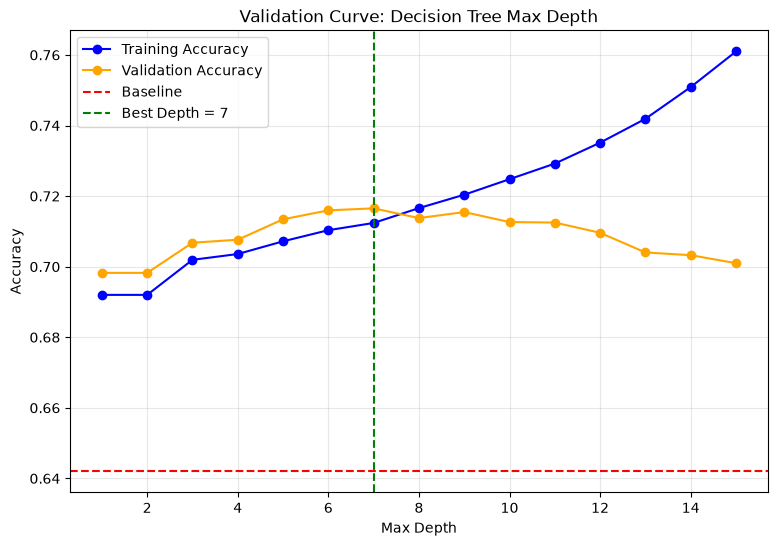

In [8]:
# Find the depth with the best validation accuracy
best_depth = list(depths)[val_accuracies.index(max(val_accuracies))]

# Plot validation curve
fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(depths, train_accuracies, 'o-', label='Training Accuracy', color='blue')
ax.plot(depths, val_accuracies, 'o-', label='Validation Accuracy', color='orange')
ax.axhline(y=baseline_acc, color='red', linestyle='--', label='Baseline')
ax.axvline(x=best_depth, color='green', linestyle='--', label=f'Best Depth = {best_depth}')
ax.set_xlabel('Max Depth')
ax.set_ylabel('Accuracy')
ax.set_title('Validation Curve: Decision Tree Max Depth')
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

9. Model Final

- Dilatih ulang dengan best_depth pada data train + validation (X_train_val), lalu diuji sekali pada test set.
- Hasil: Train 71,42%, Test 71,18%, Baseline 64,20%.

In [9]:
# Train final model with best hyperparameter
final_model = Pipeline([
    ('encoder', OrdinalEncoder()),
    ('tree', DecisionTreeClassifier(max_depth=best_depth, random_state=42))
])
final_model.fit(X_train_val, y_train_val)

# Evaluate on test set
test_acc = accuracy_score(y_test, final_model.predict(X_test))

print(f"\nFinal Model Performance:")
print(f"Training Accuracy: {accuracy_score(y_train_val, final_model.predict(X_train_val)):.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Baseline Accuracy: {baseline_acc:.4f}")


Final Model Performance:
Training Accuracy: 0.7142
Test Accuracy: 0.7118
Baseline Accuracy: 0.6420


10. Feature Importance

- feature_importances_ dari pohon, diurutkan dan diplot.
- Hasil:
    - foundation_type 64,8%
    - ground_floor_type 14,6%
    - height_ft_pre_eq 11,1%
    - age_building 5,0%
    - plinth_area_sq_ft 4,5%
    - district_id 0% (konstan)

Top 10 Most Important Features:
foundation_type      0.647751
ground_floor_type    0.145986
height_ft_pre_eq     0.110864
age_building         0.050230
plinth_area_sq_ft    0.045170
district_id          0.000000
dtype: float64


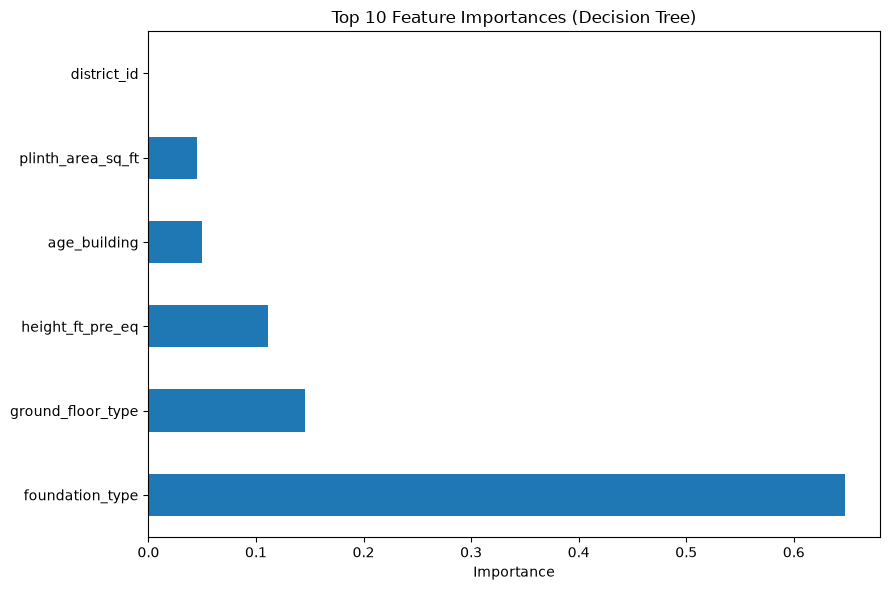

In [10]:
# Get feature importances
importances = final_model.named_steps['tree'].feature_importances_
feature_names = final_model.named_steps['encoder'].get_feature_names_out()

# Create Series and sort
feature_importance = pd.Series(importances, index=feature_names).sort_values(ascending=False)

print("Top 10 Most Important Features:")
print(feature_importance.head(10))

# Plot
fig, ax = plt.subplots(figsize=(9, 6))
feature_importance.head(10).plot(kind='barh', ax=ax)
ax.set_xlabel('Importance')
ax.set_title('Top 10 Feature Importances (Decision Tree)')
plt.tight_layout()
plt.show()

11. Visualisasi Pohon

- plot_tree(max_depth=2) → menampilkan 2 level teratas pohon keputusan, dengan warna sesuai kelas.

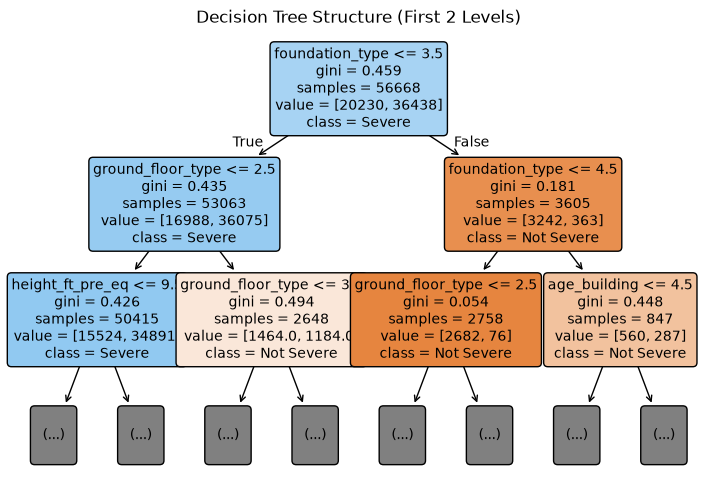

In [11]:
# Visualize the tree (first 2 levels)
fig, ax = plt.subplots(figsize=(9, 6))
plot_tree(
    final_model.named_steps['tree'],
    feature_names=feature_names,
    class_names=['Not Severe', 'Severe'],
    filled=True,
    rounded=True,
    max_depth=2,
    ax=ax,
    fontsize=10
)
ax.set_title('Decision Tree Structure (First 2 Levels)')
plt.show()

12. Perbandingan Model

- Membandingkan Baseline, Logistic Regression (dari proyek sebelumnya, 70,6%), dan Decision Tree.
- Hasil: Decision Tree menang tipis sebesar +0,0058.

In [12]:
# Note: From Lesson 2, Logistic Regression had ~70.6% test accuracy
logistic_regression_accuracy = 0.706  # From Lesson 2

print("Model Comparison:")
print("=" * 50)
print(f"{'Model':<25} {'Test Accuracy':<15}")
print("=" * 50)
print(f"{'Baseline':<25} {baseline_acc:<15.4f}")
print(f"{'Logistic Regression':<25} {logistic_regression_accuracy:<15.4f}")
print(f"{'Decision Tree':<25} {test_acc:<15.4f}")
print("=" * 50)

# Calculate improvements
print(f"\nImprovement over baseline:")
print(f"  Logistic Regression: +{logistic_regression_accuracy - baseline_acc:.4f}")
print(f"  Decision Tree: +{test_acc - baseline_acc:.4f}")

if test_acc > logistic_regression_accuracy:
    print(f"\n✓ Decision Tree wins by {test_acc - logistic_regression_accuracy:.4f}")
else:
    print(f"\n✗ Logistic Regression wins by {logistic_regression_accuracy - test_acc:.4f}")

Model Comparison:
Model                     Test Accuracy  
Baseline                  0.6420         
Logistic Regression       0.7060         
Decision Tree             0.7118         

Improvement over baseline:
  Logistic Regression: +0.0640
  Decision Tree: +0.0699

✓ Decision Tree wins by 0.0058


Kesimpulan Singkat

- Tujuan: memprediksi kerusakan parah (Grade 4-5) bangunan di Gorkha menggunakan Decision Tree dan membandingkannya dengan Logistic Regression.
- Metodologi baik: memakai pembagian train/validation/test sehingga tuning hyperparameter tidak “mengintip” data uji, lalu model final dilatih ulang pada train+validation.
- Hasil: kedalaman optimal max_depth = 7, akurasi uji 71,18%, naik ±7 poin dari baseline (64,20%).
- Perbandingan: Decision Tree (71,18%) hanya unggul sekitar 0,6 poin dari Logistic Regression (70,6%). Selisih ini kecil dan kemungkinan tidak signifikan secara praktis.
- Temuan utama: jenis pondasi (foundation_type) adalah faktor terpenting (±65%), disusul jenis lantai dasar dan tinggi bangunan. Ini konsisten dengan hasil odds ratio pada Logistic Regression.

Catatan:
- Gap train-test kecil (71,42% vs 71,18%), jadi model tidak overfitting.
- district_id tidak berguna (selalu 4), sebaiknya dihapus.
- Hanya akurasi yang dilaporkan; sebaiknya tambah precision, recall, dan AUC karena kelas tidak seimbang.
- Peningkatan lebih lanjut bisa dicoba dengan Random Forest/Gradient Boosting, penambahan fitur (jumlah lantai, jenis atap, dll.), dan tuning hyperparameter lain (min_samples_leaf, min_samples_split).